# Dialogue Summarization with a BERT-based Encoder-Decoder (SAMSum) — Final Version

The notebook follows the **CRISP-DM** process: Business Understanding (below), then Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment in the numbered sections.

## Business Understanding: The Acme Scenario

**Business problem.** Acme Communications, a messaging platform, faces information overload in group chats. Users who step away come back to dozens of unread messages, and important details get lost: decisions, times, and who agreed to do what. This notebook builds an end-to-end proof of concept that condenses messenger-style conversations into a one- or two-sentence summary that a user can read in seconds.

**Business goals.**
* Reduce information overload for users.
* Improve engagement by making conversations easier to catch up on.
* Add an AI-powered feature to the platform.

**Success criteria for the proof of concept.** Summaries that (1) score clearly above a simple extractive baseline on ROUGE, (2) name the right people and keep times and decisions correct, and (3) generate fast enough to show on demand.

**Approach.** A warm-started `EncoderDecoderModel` that pairs a pre-trained **BERT encoder** with a pre-trained **GPT-2 decoder** (the "BERT2GPT" configuration from Rothe et al., 2020). It is fine-tuned on the **SAMSum** corpus, evaluated with ROUGE against a Lead-3 baseline, and examined through error analysis and factual-consistency checks.

| Section | CRISP-DM phase | Contents |
|---|---|---|
| — | Business Understanding | The Acme scenario, goals, and success criteria (above) |
| 0 | — | Setup and configuration |
| 1 | Data Understanding, Data Preparation | Dataset exploration and cleaning |
| 2 | Data Preparation | Tokenization and data loaders |
| 3 | Modeling | Model architecture |
| 4 | Modeling | Training with early stopping and checkpointing |
| 5 | Evaluation | Decoding selection (validation) and test evaluation |
| 6 | Evaluation | Qualitative, error, and factual-consistency analysis |
| 7 | Deployment | Saving, reloading, and inference demo |
| 8 | Deployment | Findings, challenges, limitations, and next steps |

**What changed since the MVP draft** (`01_project3_mvp_draft.ipynb`). The draft model learned the *format* of a summary but ignored the conversation: it scored below the Lead-3 baseline (ROUGE-L 13.1 vs 24.2), and 95.5% of its summaries contained invented names. This version addresses the likely causes:
* **Dedicated `[PAD]` token for GPT-2.** In the draft, `<|endoftext|>` was both the padding token and the decoder start token, so the start position was masked out during training but not during generation.
* **Higher learning rate (`1e-4`)** so the randomly initialized cross-attention layers learn faster.
* **Full training set** (14.7k dialogues instead of 3,000), run on a Colab T4 rather than a 4 GB local GPU.
* **Practical fixes from the draft run:** `datasets` 4.x columns converted with `list(...)`, data-loader workers disabled on Windows, generation capped at `MAX_NEW_TOKENS`, and the draft's results kept in `results/mvp_test_results.csv` for comparison (Section 8.4).

**Result.** On the 819-dialogue test set, the final model (beam search, selected on validation data) reaches **ROUGE-1 / ROUGE-2 / ROUGE-L of 37.5 / 14.1 / 30.4**. It beats the Lead-3 baseline by **6.2 ROUGE-L** (95% bootstrap CI +5.1 to +7.2), up from a ROUGE-L of 13.1 in the MVP draft. Summaries with invented names fell from 95.5% to 49.5%; names remain the main weakness (Section 6).

**How to run.** This notebook lives in the repository's `notebooks/` folder and writes its outputs one level up: figures to `figures/`, metrics and example summaries to `results/`, the model to `models/`, and checkpoints to `checkpoints/`. Paths are resolved automatically whether you start Jupyter in the repository root or in `notebooks/`.
* **Google Colab (recommended):** clone the repository, `%cd` into its `notebooks/` folder, select *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Full-dataset training takes roughly 1–2 hours on a T4.
* **Locally:** a CUDA GPU is required in practice; on the 4 GB GTX 1650 SUPER used for the draft, even the 3,000-dialogue subset took 3.7 hours.
* Set `USE_SUBSET = True` for a quick test run. The results section of `README.md` is updated automatically at the end.

## 0. Setup

In [1]:
!pip install -q "transformers>=4.44,<5" "datasets>=2.20" evaluate rouge_score nltk accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 114.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 117.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


*Note:* the red `ERROR` above is a pip dependency **warning**, not a failure. Colab preinstalls `gradio` and `diffusers`, which prefer a newer `huggingface-hub` than the version `transformers<5` installs. Neither library is used in this notebook, and the installation completed successfully.

In [1]:
import os, re, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

import nltk
import evaluate
import transformers
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    EncoderDecoderModel,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
    set_seed,
)

# EncoderDecoderModel emits a one-off FutureWarning about how it builds decoder inputs from labels
# (a behaviour change from v4.12). It does not affect models trained from scratch, as here.
warnings.filterwarnings("ignore", message=".*Version v4.12.0 introduces a better way.*")

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

SEED = 42
set_seed(SEED)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
print("transformers:", transformers.__version__, "| torch:", torch.__version__)
print("device:", device, "|", GPU_NAME)

transformers: 4.57.6 | torch: 2.11.0+cu130
device: cuda | Tesla T4


### Configuration
All design choices live in one cell so experiments are easy to reproduce.

* **Encoder:** `bert-base-uncased`, a pre-trained bidirectional encoder that reads the whole dialogue.
* **Decoder:** `gpt2`, a pre-trained autoregressive generator. Its cross-attention layers, which let it attend to the BERT encoding, are newly initialized and learned during fine-tuning. Setting `DECODER_NAME = "bert-base-uncased"` runs the BERT2BERT variant instead; every later cell handles both.
* **Data:** the final run uses all ~14.7k training dialogues. `USE_SUBSET = True` trains on 3,000 for fast iteration (the MVP draft's setting).
* **Learning rate:** `1e-4`, up from the draft's `5e-5`. The draft's validation ROUGE-L rose only from 11.5 to 12.3 between steps 400 and 800, a sign that the new cross-attention layers were learning too slowly.
* **Outputs:** set `USE_GOOGLE_DRIVE = True` on Colab so checkpoints survive a disconnect, and `PUSH_TO_HUB = True` to publish the weights to the Hugging Face Hub.

In [2]:
# ---- Model ----
ENCODER_NAME = "bert-base-uncased"
DECODER_NAME = "gpt2"              # "bert-base-uncased" -> BERT2BERT variant

# ---- Sequence lengths (justified by the token-length check in Section 2) ----
MAX_INPUT_LEN = 512                # BERT's position-embedding limit
MAX_TARGET_LEN = 128               # longest training summary that is kept
MAX_NEW_TOKENS = 80                # generation cap; the longest summaries in a 2,000-sample check were 77 tokens

# ---- Data size ----
USE_SUBSET = False                 # True -> 3,000 training dialogues for quick experiments
TRAIN_SUBSET_SIZE = 3000
VAL_EVAL_SIZE = 200                # validation dialogues scored with ROUGE during training and decoding selection

# ---- Optimization ----
BATCH_SIZE = 8
GRAD_ACCUM = 2                     # effective batch size 16
LEARNING_RATE = 1e-4               # draft used 5e-5; higher helps the new cross-attention layers learn
NUM_EPOCHS = 5
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
EVAL_STEPS = 200 if USE_SUBSET else 500
PATIENCE = 3                       # early stopping: evaluations without a ROUGE-L improvement

# ---- Outputs (the notebook lives in notebooks/; outputs go to the repository root) ----
PROJECT_ROOT = ".." if os.path.basename(os.path.abspath(".")) == "notebooks" else "."
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "checkpoints", "bert2gpt2-samsum-final-run")
FINAL_MODEL_DIR = os.path.join(PROJECT_ROOT, "models", "bert2gpt2-samsum-v2")   # the draft's model stays in models/bert2gpt2-samsum-final
FIG_DIR = os.path.join(PROJECT_ROOT, "figures")
RESULTS_DIR = os.path.join(PROJECT_ROOT, "results")
README_PATH = os.path.join(PROJECT_ROOT, "README.md")
NUM_WORKERS = 0 if os.name == "nt" else 2   # multi-process data loading can hang Jupyter on Windows
RESUME_FROM_CHECKPOINT = False     # True -> continue from the latest checkpoint in OUTPUT_DIR
USE_GOOGLE_DRIVE = True
DRIVE_DIR = "/content/drive/MyDrive/samsum-project"
PUSH_TO_HUB = False
HUB_REPO_ID = "your-username/bert2gpt2-samsum"

In [4]:
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = os.path.join(DRIVE_DIR, "checkpoints")
    FINAL_MODEL_DIR = os.path.join(DRIVE_DIR, "final_model")

for d in (FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure to figures/<name>.png (used by the README)."""
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

Mounted at /content/drive


## 1. Data Understanding and Data Preparation: Dataset Exploration and Cleaning

SAMSum (Gliwa et al., 2019) contains about 16k messenger-style conversations written by linguists, each with a human-written abstractive summary. It comes with standard train / validation / test splits.

In [5]:
raw = load_dataset("knkarthick/samsum")
print(raw)

ex = raw["train"][0]
print("\n--- DIALOGUE ---\n" + ex["dialogue"])
print("\n--- SUMMARY ---\n" + ex["summary"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 14731
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 818
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary'],
        num_rows: 819
    })
})

--- DIALOGUE ---
Amanda: I baked  cookies. Do you want some?
Jerry: Sure!
Amanda: I'll bring you tomorrow :-)

--- SUMMARY ---
Amanda baked cookies and will bring Jerry some tomorrow.


### Cleaning (Data Preparation)
SAMSum contains Windows line endings, placeholder tokens such as `<file_photo>`, and a few empty records. We normalize whitespace, turn file placeholders into short readable tags (`[photo]`) that the tokenizers will not split into noise, and drop empty examples. The same `clean_text` function is applied at inference time so training and deployment see identical input.

In [6]:
def clean_text(t):
    """Normalize line endings and whitespace and make file placeholders readable."""
    if t is None:
        return ""
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = re.sub(r"<file_(\w+)>", r"[\1]", t)      # <file_photo> -> [photo]
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\n+", "\n", t)
    return t.strip()

def clean_example(ex):
    return {"dialogue": clean_text(ex["dialogue"]), "summary": clean_text(ex["summary"])}

before = {k: len(v) for k, v in raw.items()}
ds = raw.map(clean_example)
ds = ds.filter(lambda ex: len(ex["dialogue"]) > 0 and len(ex["summary"]) > 0)
after = {k: len(v) for k, v in ds.items()}
print("before:", before)
print("after: ", after)

before: {'train': 14731, 'validation': 818, 'test': 819}
after:  {'train': 14731, 'validation': 818, 'test': 819}


### Dialogue and summary characteristics (Data Understanding)

In [7]:
SPEAKER_RE = re.compile(r"^([^:\n]{1,40}):", re.MULTILINE)

def speakers_of(dialogue):
    """Set of speaker names, taken from the 'Name:' prefix of each line."""
    return {s.strip() for s in SPEAKER_RE.findall(dialogue)}

def dialogue_stats(df):
    df = df.copy()
    df["dlg_words"] = df["dialogue"].str.split().str.len()
    df["sum_words"] = df["summary"].str.split().str.len()
    df["turns"] = df["dialogue"].str.count("\n") + 1
    df["speakers"] = df["dialogue"].apply(lambda d: len(speakers_of(d)))
    df["compression"] = df["sum_words"] / df["dlg_words"]
    return df

train_df = dialogue_stats(ds["train"].to_pandas())
train_df[["dlg_words", "sum_words", "turns", "speakers", "compression"]] \
    .describe(percentiles=[.5, .9, .95, .99]).round(2)

,dlg_words,sum_words,turns,speakers,compression
count,14731.00,14731.00,14731.00,14731.00,14731.00
mean,93.79,20.32,11.17,2.39,0.30
std,74.03,11.15,6.45,0.83,0.18
min,7.00,1.00,3.00,2.00,0.02
50%,73.00,18.00,10.00,2.00,0.26
90%,191.00,37.00,20.00,3.00,0.53
95%,237.00,43.00,24.00,4.00,0.64
99%,351.00,53.00,29.00,5.00,0.87
max,803.00,64.00,46.00,14.00,1.89


In [8]:
print("Speakers per dialogue (% of training set):")
print((train_df["speakers"].clip(upper=6).value_counts(normalize=True).sort_index() * 100).round(1)
      .rename(index={6: "6+"}))

Speakers per dialogue (% of training set):
speakers
2     73.0
3     19.1
4      5.6
5      1.3
6+     1.0
Name: proportion, dtype: float64


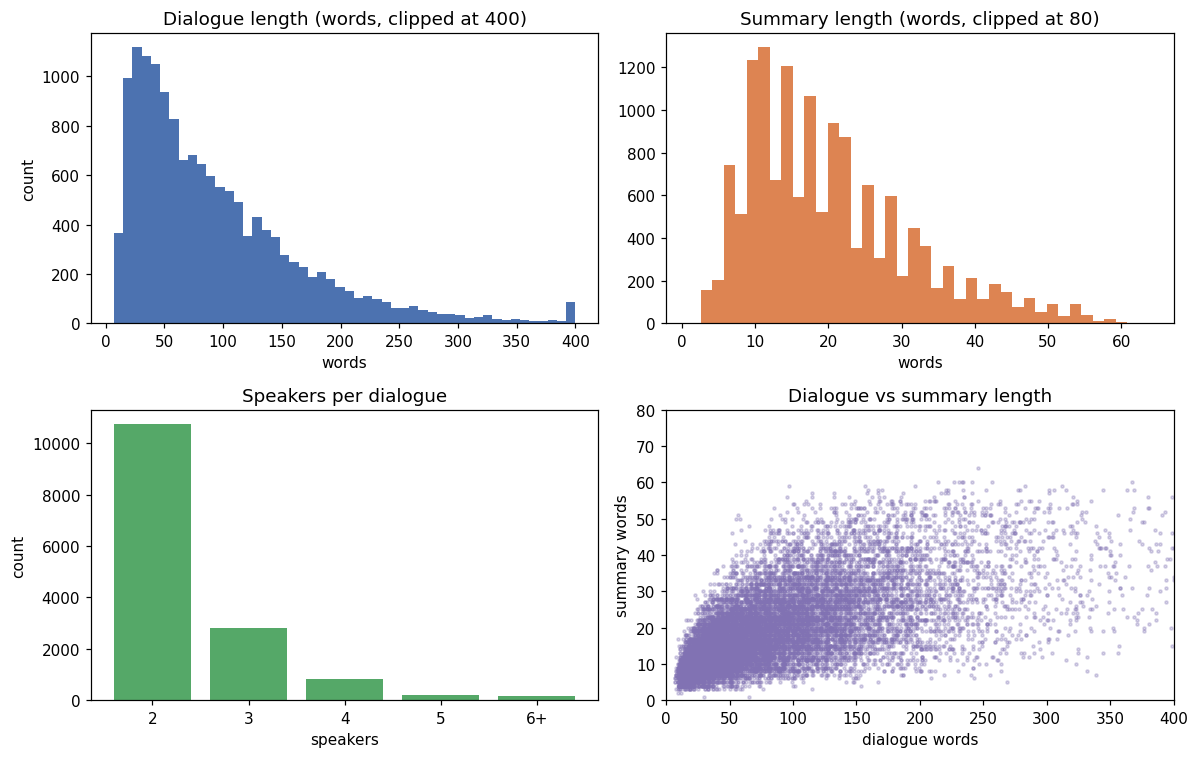

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].hist(train_df["dlg_words"].clip(upper=400), bins=50, color="#4C72B0")
axes[0, 0].set(title="Dialogue length (words, clipped at 400)", xlabel="words", ylabel="count")

axes[0, 1].hist(train_df["sum_words"].clip(upper=80), bins=40, color="#DD8452")
axes[0, 1].set(title="Summary length (words, clipped at 80)", xlabel="words")

spk = train_df["speakers"].clip(upper=6).value_counts().sort_index()
axes[1, 0].bar([str(i) if i < 6 else "6+" for i in spk.index], spk.values, color="#55A868")
axes[1, 0].set(title="Speakers per dialogue", xlabel="speakers", ylabel="count")

axes[1, 1].scatter(train_df["dlg_words"], train_df["sum_words"], s=4, alpha=0.3, color="#8172B3")
axes[1, 1].set(title="Dialogue vs summary length", xlabel="dialogue words", ylabel="summary words",
               xlim=(0, 400), ylim=(0, 80))

plt.tight_layout()
save_fig("data_overview")
plt.show()

**Observations**
* **Short inputs with a long tail.** Most dialogues are brief chat exchanges of under ~100 words, but the tail reaches several hundred words. That tail matters for Acme's long group chats and for BERT's 512-token limit (checked in Section 2).
* **Very short targets.** Summaries are typically one or two third-person sentences of around 20 words, so the model must compress the dialogue several-fold (see the `compression` column).
* **Mostly two speakers.** Two-person chats dominate. Group chats with 3+ speakers are a minority, yet they are exactly Acme's use case, so Section 6 reports performance for them separately.
* **Abstractive summaries.** References rewrite first-person chat ("I'll bring the cake") as third-person reports ("Amanda will bring the cake"), so copying lines cannot work well. This motivates a generative model and the extractive Lead-3 baseline as a lower bound.
* **Length correlation is weak.** The scatter plot shows summary length grows only slightly with dialogue length, so a fixed generation budget of 128 tokens is ample.

## 2. Data Preparation: Tokenization and Data Loaders

The encoder and decoder have **different vocabularies**, so each side uses its own tokenizer:
* Dialogues → BERT WordPiece tokenizer (`[CLS] … [SEP]`).
* Summaries → GPT-2 byte-level BPE tokenizer. `<|endoftext|>` serves as the decoder start token and the end-of-summary token.

**Padding fix from the MVP draft.** GPT-2 has no padding token. The draft reused `<|endoftext|>` for padding as well, but `EncoderDecoderModel` builds the decoder attention mask during training by masking every padding token, and that also masked the *start* token at position 0. Generation doesn't apply that mask, so training and inference saw the first position differently. Here GPT-2 gets its own `[PAD]` token, and its embedding matrix is resized to match in Section 3.

In [10]:
enc_tok = AutoTokenizer.from_pretrained(ENCODER_NAME)
dec_tok = AutoTokenizer.from_pretrained(DECODER_NAME)
IS_GPT2_DECODER = "gpt2" in DECODER_NAME.lower()

if IS_GPT2_DECODER:
    dec_tok.add_special_tokens({"pad_token": "[PAD]"})   # dedicated pad token (fix from the MVP draft)
    DEC_START_ID = dec_tok.bos_token_id      # <|endoftext|>
    EOS_ID = dec_tok.eos_token_id            # <|endoftext|>
    PAD_ID = dec_tok.pad_token_id            # [PAD], no longer the same as the start token
    assert PAD_ID != DEC_START_ID
else:                                        # BERT2BERT
    DEC_START_ID = dec_tok.cls_token_id
    EOS_ID = dec_tok.sep_token_id
    PAD_ID = dec_tok.pad_token_id

print(f"decoder start={DEC_START_ID}, eos={EOS_ID}, pad={PAD_ID}, decoder vocab={len(dec_tok)}")

decoder start=50256, eos=50256, pad=50257, decoder vocab=50258


In [11]:
# How much of the data fits within the length limits?
# list(...) is needed because datasets 4.x returns a Column object, which tokenizers reject
sample = ds["train"].shuffle(seed=SEED).select(range(2000))
in_lens = np.array([len(x) for x in enc_tok(list(sample["dialogue"]))["input_ids"]])
out_lens = np.array([len(x) + 1 for x in dec_tok(list(sample["summary"]), add_special_tokens=False)["input_ids"]])

for name, lens, limit in [("dialogue (BERT tokens)", in_lens, MAX_INPUT_LEN),
                          ("summary (GPT-2 tokens)", out_lens, MAX_TARGET_LEN)]:
    print(f"{name}: median={np.median(lens):.0f}, p95={np.percentile(lens, 95):.0f}, "
          f"max={lens.max()}, fits in {limit}: {(lens <= limit).mean() * 100:.1f}%")

Token indices sequence length is longer than the specified maximum sequence length for this model (616 > 512). Running this sequence through the model will result in indexing errors


dialogue (BERT tokens): median=108, p95=337, max=797, fits in 512: 99.0%
summary (GPT-2 tokens): median=23, p95=53, max=77, fits in 128: 100.0%


In [12]:
def preprocess(batch):
    """Tokenize dialogues for the encoder and summaries (plus an end token) as decoder labels."""
    model_inputs = enc_tok(
        batch["dialogue"],
        max_length=MAX_INPUT_LEN,
        truncation=True,
        return_token_type_ids=False,
    )
    targets = dec_tok(
        batch["summary"],
        add_special_tokens=False,
        max_length=MAX_TARGET_LEN - 1,
        truncation=True,
    )["input_ids"]
    # An explicit end-of-summary token teaches the model when to stop generating
    model_inputs["labels"] = [ids + [EOS_ID] for ids in targets]
    return model_inputs

train_raw = ds["train"].shuffle(seed=SEED)
if USE_SUBSET:
    train_raw = train_raw.select(range(min(TRAIN_SUBSET_SIZE, len(train_raw))))
val_eval_raw = ds["validation"].shuffle(seed=SEED).select(range(min(VAL_EVAL_SIZE, len(ds["validation"]))))
test_raw = ds["test"]

cols = ds["train"].column_names
train_tok = train_raw.map(preprocess, batched=True, remove_columns=cols)
val_eval_tok = val_eval_raw.map(preprocess, batched=True, remove_columns=cols)

print(f"train: {len(train_tok)} | validation (ROUGE during training): {len(val_eval_tok)} | test: {len(test_raw)}")

train: 14731 | validation (ROUGE during training): 200 | test: 819


**Data loaders.** We use *dynamic padding*: each batch is padded only to its longest example instead of always to 512 tokens, which cuts compute substantially because most dialogues are short. Label padding uses `-100`, so padded positions are ignored by the loss. On GPU, lengths are rounded up to a multiple of 8 for faster fp16 matrix multiplies.

In [13]:
collator = DataCollatorForSeq2Seq(
    tokenizer=enc_tok,
    label_pad_token_id=-100,
    pad_to_multiple_of=8 if device.type == "cuda" else None,
)

# Explicit DataLoader to inspect one batch (the Trainer builds equivalent loaders internally)
train_loader = DataLoader(train_tok, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator)
batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:15s} {tuple(v.shape)}")

print("\nDecoded input :", enc_tok.decode(batch["input_ids"][0], skip_special_tokens=True)[:250], "...")
lbl = batch["labels"][0]
print("Decoded target:", dec_tok.decode(lbl[lbl != -100]))

input_ids       (8, 216)
attention_mask  (8, 216)
labels          (8, 40)

Decoded input : stella : you play pubg on cellphone? blake : used to play but deleted it yesterday stella : welldone ...
Decoded target: Blake deleted PUBG from his phone yesterday.<|endoftext|>


## 3. Modeling: Model Architecture

```
 dialogue ──► BERT tokenizer ──► BERT encoder (12 layers, pre-trained)
                                        │  contextual embeddings (768-d per token)
                                        ▼
 <|endoftext|> ─► GPT-2 decoder (12 layers, pre-trained self-attention
                  + NEW cross-attention to encoder outputs) ──► LM head ──► summary tokens
```

* **Encoder (BERT):** bidirectional; produces a contextual representation of every dialogue token, so each turn is read in the context of the whole conversation.
* **Decoder (GPT-2):** autoregressive; at each step it attends to previously generated tokens (masked self-attention) and to the encoder output (cross-attention).
* **Warm-starting:** both stacks keep their pre-trained weights. Only the cross-attention layers start random. Loading normally prints a warning about these newly initialized weights; it is expected, so we silence it for this one call.
* **Resized decoder vocabulary:** GPT-2's embedding and output layers gain one row for the new `[PAD]` token.
* **Loss:** token-level cross-entropy with teacher forcing (`labels` are shifted right internally to form the decoder inputs).

**Why BERT2GPT rather than BERT2BERT?** The brief asks for a BERT-based encoder-decoder. Both options use BERT as the encoder. Rothe et al. (2020) show that BERT encoders pair well with GPT-2 decoders, and GPT-2 was pre-trained as a left-to-right generator, whereas a BERT decoder must learn generation from scratch during fine-tuning. The BERT2BERT variant remains one config change away for comparison.

In [14]:
transformers.logging.set_verbosity_error()   # hide the expected "newly initialized cross-attention" notice
model = EncoderDecoderModel.from_encoder_decoder_pretrained(ENCODER_NAME, DECODER_NAME)
transformers.logging.set_verbosity_warning()

if IS_GPT2_DECODER:
    model.decoder.resize_token_embeddings(len(dec_tok))   # add a row for the new [PAD] token

# Special tokens the seq2seq wrapper needs. Missing these is the most common cause of garbage output.
model.config.decoder_start_token_id = DEC_START_ID
model.config.eos_token_id = EOS_ID
model.config.pad_token_id = PAD_ID
model.config.vocab_size = model.config.decoder.vocab_size

gen_cfg = model.generation_config
gen_cfg.decoder_start_token_id = DEC_START_ID
gen_cfg.eos_token_id = EOS_ID
gen_cfg.pad_token_id = PAD_ID

model.to(device)

def n_params(params):
    return sum(p.numel() for p in params)

total = n_params(model.parameters())
enc_p = n_params(model.encoder.parameters())
dec_p = n_params(model.decoder.parameters())
xattn = sum(p.numel() for n, p in model.decoder.named_parameters() if "cross" in n)
print(f"Total params:          {total / 1e6:7.1f}M")
print(f"  Encoder (BERT):      {enc_p / 1e6:7.1f}M")
print(f"  Decoder:             {dec_p / 1e6:7.1f}M")
print(f"    new cross-attn:    {xattn / 1e6:7.1f}M  (randomly initialized)")

The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


Total params:            262.3M
  Encoder (BERT):        109.5M
  Decoder:               152.8M
    new cross-attn:       28.4M  (randomly initialized)


In [15]:
# Sanity check: one forward pass, plus generation BEFORE fine-tuning (expect nonsense)
model.eval()
with torch.no_grad():
    small = {k: v[:2].to(device) for k, v in batch.items()}
    print("Initial loss on one batch:", round(model(**small).loss.item(), 3))
    out = model.generate(input_ids=small["input_ids"], attention_mask=small["attention_mask"], max_new_tokens=30)
print("Untrained output:", dec_tok.decode(out[0], skip_special_tokens=True))

/usr/local/lib/python3.13/dist-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)


Initial loss on one batch: 5.116
Untrained output: 
The U.S. Department of Justice has filed a lawsuit against the company that owns the video game company, Electronic Arts, alleging that the company


## 4. Modeling: Training and Optimization

* **Optimizer:** AdamW with a peak learning rate of `1e-4`, linear warm-up over the first 10% of steps, then linear decay; weight decay 0.01. Warm-up protects the pre-trained weights from large early updates driven by the randomly initialized cross-attention.
* **Efficiency:** mixed precision (fp16), gradient accumulation (effective batch 16), and dynamic padding keep training within a free T4.
* **Monitoring:** training loss every 25 steps; every `EVAL_STEPS` steps we compute validation loss **and** ROUGE on 200 held-out dialogues (greedy decoding, for speed).
* **Checkpointing:** a checkpoint is saved at every evaluation (the 2 most recent plus the best are kept), so a Colab disconnect can be resumed with `RESUME_FROM_CHECKPOINT = True`.
* **Early stopping and model selection:** training stops if validation ROUGE-L fails to improve for `PATIENCE` evaluations, and the best checkpoint is restored at the end. We select on ROUGE-L rather than loss because loss measures teacher-forced prediction, while ROUGE measures the summaries users would actually see.

In [16]:
rouge = evaluate.load("rouge")

def _sent_split(texts):
    # rougeLsum expects one sentence per line
    return ["\n".join(nltk.sent_tokenize(t.strip())) for t in texts]

def compute_rouge(preds, refs, aggregate=True):
    """ROUGE F1 x 100. aggregate=False returns per-example score lists."""
    r = rouge.compute(predictions=_sent_split(preds), references=_sent_split(refs),
                      use_stemmer=True, use_aggregator=aggregate)
    if aggregate:
        return {k: round(v * 100, 2) for k, v in r.items()}
    return {k: [x * 100 for x in v] for k, v in r.items()}

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds < 0, PAD_ID, preds)
    labels = np.where(labels != -100, labels, PAD_ID)
    pred_str = [p.strip() for p in dec_tok.batch_decode(preds, skip_special_tokens=True)]
    ref_str = [r.strip() for r in dec_tok.batch_decode(labels, skip_special_tokens=True)]
    res = compute_rouge(pred_str, ref_str)
    res["gen_words"] = round(float(np.mean([len(p.split()) for p in pred_str])), 1)
    return res

In [17]:
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    lr_scheduler_type="linear",
    num_train_epochs=NUM_EPOCHS,
    eval_strategy="steps",
    eval_steps=EVAL_STEPS,
    save_strategy="steps",
    save_steps=EVAL_STEPS,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    logging_steps=25,
    predict_with_generate=True,
    generation_max_length=MAX_NEW_TOKENS,
    generation_num_beams=1,
    fp16=torch.cuda.is_available(),
    save_safetensors=False,          # checkpoints: avoids a shared-tensor error with GPT-2's tied embeddings
    dataloader_num_workers=NUM_WORKERS,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_eval_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)],
)

steps_per_epoch = int(np.ceil(len(train_tok) / (BATCH_SIZE * GRAD_ACCUM)))
print(f"{steps_per_epoch} optimizer steps/epoch, up to {steps_per_epoch * NUM_EPOCHS} total")

921 optimizer steps/epoch, up to 4605 total


In [18]:
t0 = time.time()
train_result = trainer.train(resume_from_checkpoint=RESUME_FROM_CHECKPOINT or None)
train_minutes = (time.time() - t0) / 60
model = trainer.model                         # best checkpoint, restored by load_best_model_at_end
print(f"Training time: {train_minutes:.1f} min")
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best val ROUGE-L:", trainer.state.best_metric)

# Save the best model in a shareable format, with both tokenizers and the training log
os.makedirs(FINAL_MODEL_DIR, exist_ok=True)
try:
    model.save_pretrained(FINAL_MODEL_DIR, safe_serialization=True)
    WEIGHTS_FORMAT = "safetensors"
except Exception as e:                        # older versions reject GPT-2's tied weights in safetensors
    print(f"safetensors export failed ({type(e).__name__}); saving PyTorch .bin instead")
    model.save_pretrained(FINAL_MODEL_DIR, safe_serialization=False)
    WEIGHTS_FORMAT = "pytorch .bin"
enc_tok.save_pretrained(os.path.join(FINAL_MODEL_DIR, "encoder_tokenizer"))
dec_tok.save_pretrained(os.path.join(FINAL_MODEL_DIR, "decoder_tokenizer"))
with open(os.path.join(FINAL_MODEL_DIR, "log_history.json"), "w") as f:
    json.dump(trainer.state.log_history, f, indent=1)

size_mb = sum(os.path.getsize(os.path.join(dp, fn))
              for dp, _, fns in os.walk(FINAL_MODEL_DIR) for fn in fns) / 1e6
print(f"Saved to {FINAL_MODEL_DIR} ({WEIGHTS_FORMAT}, {size_mb:.0f} MB)")

/usr/local/lib/python3.13/dist-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)


Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Gen Words
500,6.958800,3.412318,14.760000,2.080000,12.140000,13.600000,29.300000
1000,5.726200,3.162860,21.240000,4.170000,17.580000,19.250000,15.000000
1500,5.432100,2.940388,24.420000,6.020000,20.260000,22.360000,15.400000
2000,4.320100,2.855993,29.060000,8.250000,23.330000,26.410000,16.300000
2500,4.234300,2.755755,31.410000,9.480000,26.190000,28.790000,14.800000
3000,3.464600,2.769068,33.580000,11.010000,27.540000,30.400000,14.500000
3500,3.380900,2.733239,35.480000,12.420000,28.360000,32.160000,16.300000
4000,2.893400,2.795682,35.260000,12.290000,28.610000,31.660000,14.900000
4500,2.768500,2.788105,36.190000,12.410000,28.990000,32.640000,16.600000


/usr/local/lib/python3.13/dist-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)
/usr/local/lib/python3.13/dist-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than tensor.new_tensor(sourceTensor).
  decoder_attention_mask = decoder_input_ids.new_tensor(decoder_input_ids != self.config.pad_token_id)
/usr/local/lib/python3.13/dist-packages/transformers/models/encoder_decoder/modeling_encoder_decoder.py:555: UserWarning: To copy construct from a tensor, it is recommended t

Training time: 43.5 min
Best checkpoint: /content/drive/MyDrive/samsum-project/checkpoints/checkpoint-4500
Best val ROUGE-L: 28.99
Saved to /content/drive/MyDrive/samsum-project/final_model (safetensors, 1055 MB)


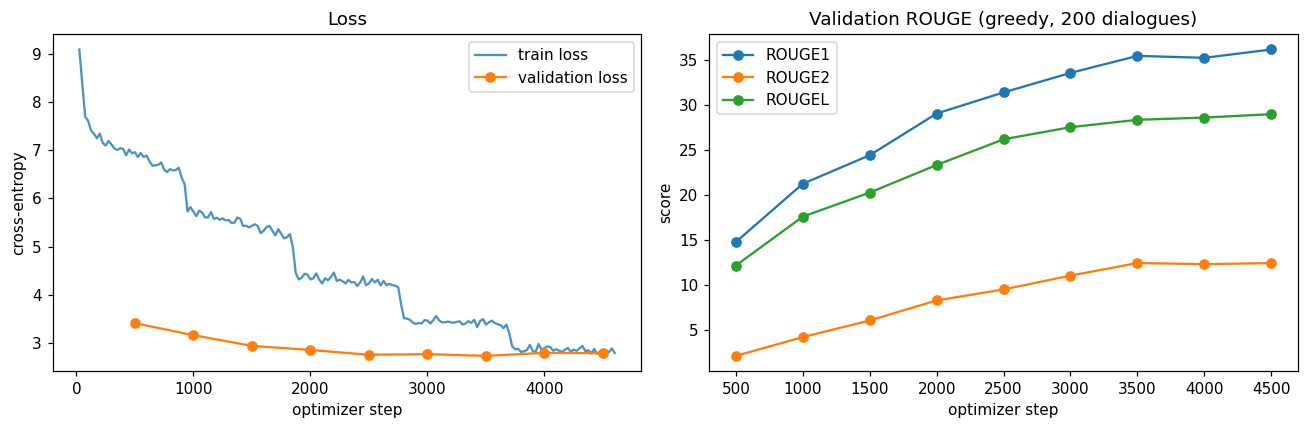

,step,eval_loss,eval_rouge1,eval_rouge2,eval_rougeL,eval_gen_words
20,500,3.41,14.76,2.08,12.14,29.3
41,1000,3.16,21.24,4.17,17.58,15.0
62,1500,2.94,24.42,6.02,20.26,15.4
83,2000,2.86,29.06,8.25,23.33,16.3
104,2500,2.76,31.41,9.48,26.19,14.8
125,3000,2.77,33.58,11.01,27.54,14.5
146,3500,2.73,35.48,12.42,28.36,16.3
167,4000,2.80,35.26,12.29,28.61,14.9
188,4500,2.79,36.19,12.41,28.99,16.6


In [19]:
hist = pd.DataFrame(trainer.state.log_history)
train_log = hist[hist["loss"].notna()] if "loss" in hist else pd.DataFrame()
eval_log = hist[hist["eval_loss"].notna()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if len(train_log):
    axes[0].plot(train_log["step"], train_log["loss"], label="train loss", alpha=0.8)
axes[0].plot(eval_log["step"], eval_log["eval_loss"], "o-", label="validation loss")
axes[0].set(title="Loss", xlabel="optimizer step", ylabel="cross-entropy")
axes[0].legend()

for m in ["eval_rouge1", "eval_rouge2", "eval_rougeL"]:
    axes[1].plot(eval_log["step"], eval_log[m], "o-", label=m.replace("eval_", "").upper())
axes[1].set(title=f"Validation ROUGE (greedy, {len(val_eval_tok)} dialogues)", xlabel="optimizer step", ylabel="score")
axes[1].legend()
plt.tight_layout()
save_fig("training_curves")
plt.show()

eval_log[["step", "eval_loss", "eval_rouge1", "eval_rouge2", "eval_rougeL", "eval_gen_words"]].round(2)

**Reading the curves.** Training loss should fall steadily. Validation ROUGE usually rises quickly in the first epoch, as the cross-attention learns to use the encoder, and then flattens. If validation loss starts rising while ROUGE stays flat, the model is beginning to overfit, and early stopping plus best-checkpoint restoration guard against it.

**In this run**, validation ROUGE-L rose from 12.1 at step 500 to 29.0 at step 4,500 and was still improving slightly at the end, so early stopping never triggered and the best checkpoint was the last evaluation (step 4,500). Validation loss was lowest at step 3,500 (2.73) and drifted up slightly afterwards while training loss kept falling: mild overfitting, which selecting checkpoints on ROUGE-L rather than loss guards against. Training took 44 minutes on a Tesla T4.

## 5. Evaluation: Decoding Selection and Test-Set Results

### 5.1 Choosing a decoding strategy on validation data
The decoding strategy is a hyperparameter, so we select it on the **validation** set and only then report on the test set. Choosing it on the test set would leak test information into the reported score.

* **Greedy:** picks the most likely token at each step; fast but can be repetitive.
* **Beam search (4 beams):** keeps the 4 best partial summaries and blocks repeated trigrams.
* **Beam search + length penalty 2.0:** nudges beams toward longer, more complete summaries.

In [20]:
@torch.no_grad()
def generate_summaries(dialogues, mdl=None, etok=None, dtok=None,
                       batch_size=16, max_new_tokens=MAX_NEW_TOKENS, **gen_kwargs):
    """Summarize a list of dialogues. Defaults to the in-memory model and tokenizers."""
    mdl = model if mdl is None else mdl
    etok = enc_tok if etok is None else etok
    dtok = dec_tok if dtok is None else dtok
    mdl.eval()
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        enc = etok(dialogues[i:i + batch_size], max_length=MAX_INPUT_LEN, truncation=True,
                   padding=True, return_token_type_ids=False, return_tensors="pt").to(device)
        ids = mdl.generate(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"],
                           max_new_tokens=max_new_tokens, **gen_kwargs)
        outputs.extend(s.strip() for s in dtok.batch_decode(ids, skip_special_tokens=True))
    return outputs

def lead3(dialogue):
    """Extractive baseline: the first three chat lines."""
    return "\n".join(dialogue.split("\n")[:3])

DECODING = {
    "greedy":      dict(num_beams=1, do_sample=False),
    "beam4":       dict(num_beams=4, no_repeat_ngram_size=3, early_stopping=True),
    "beam4_lp2.0": dict(num_beams=4, no_repeat_ngram_size=3, early_stopping=True, length_penalty=2.0),
}

sel_rows = []
for name, kw in DECODING.items():
    p = generate_summaries(list(val_eval_raw["dialogue"]), **kw)
    r = compute_rouge(p, list(val_eval_raw["summary"]))
    sel_rows.append({"decoding": name, **r, "avg_words": round(float(np.mean([len(x.split()) for x in p])), 1)})
selection_df = pd.DataFrame(sel_rows).set_index("decoding")
selection_df.to_csv(os.path.join(RESULTS_DIR, "decoding_selection_validation.csv"))

BEST = selection_df["rougeL"].idxmax()
print("Decoding strategy selected on validation:", BEST)
selection_df

Decoding strategy selected on validation: beam4


,rouge1,rouge2,rougeL,rougeLsum,avg_words
decoding,,,,,
greedy,36.12,12.39,28.98,32.59,16.6
beam4,37.75,14.06,30.60,34.13,15.6
beam4_lp2.0,37.84,13.88,30.34,34.15,18.0


### 5.2 Test-set results
All strategies are reported on the full test set (819 dialogues) for transparency, but **the headline result is the strategy selected above**. The Lead-3 baseline returns the first three chat lines, a standard extractive baseline for SAMSum. `ms_per_dialogue` is measured with batches of 16 on the current GPU.

In [21]:
test_dialogues = list(test_raw["dialogue"])   # list(...): datasets 4.x returns a Column object
test_refs = list(test_raw["summary"])
REF_AVG_WORDS = float(np.mean([len(x.split()) for x in test_refs]))

preds = {"lead3_baseline": [lead3(d) for d in test_dialogues]}
timings = {"lead3_baseline": 0.0}
for name, kw in DECODING.items():
    t0 = time.time()
    preds[name] = generate_summaries(test_dialogues, **kw)
    timings[name] = time.time() - t0
    print(f"{name:12s} done in {timings[name]:.0f}s")

rows = []
for name, p in preds.items():
    r = compute_rouge(p, test_refs)
    r["avg_words"] = round(float(np.mean([len(x.split()) for x in p])), 1)
    r["ms_per_dialogue"] = round(1000 * timings[name] / len(p), 1)
    rows.append({"method": name, **r})

results_df = pd.DataFrame(rows).set_index("method")
results_df.to_csv(os.path.join(RESULTS_DIR, "test_results.csv"))
print(f"Reference summaries average {REF_AVG_WORDS:.1f} words")
results_df

greedy       done in 68s
beam4        done in 111s
beam4_lp2.0  done in 111s
Reference summaries average 20.0 words


,rouge1,rouge2,rougeL,rougeLsum,avg_words,ms_per_dialogue
method,,,,,,
lead3_baseline,31.34,8.68,24.21,29.67,23.6,0.0
greedy,36.24,12.99,29.39,32.90,16.2,83.0
beam4,37.49,14.09,30.42,34.02,15.3,136.1
beam4_lp2.0,37.71,13.71,30.00,34.09,17.7,135.9


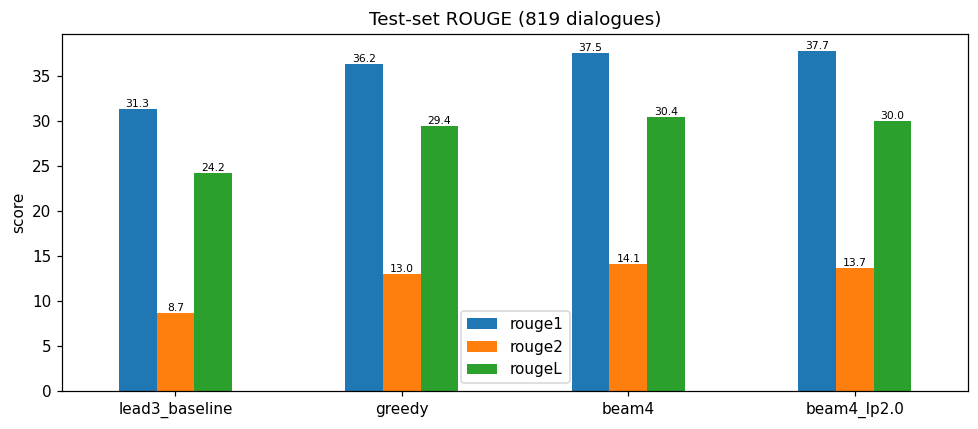

In [22]:
ax = results_df[["rouge1", "rouge2", "rougeL"]].plot.bar(figsize=(9, 4), rot=0)
ax.set(title=f"Test-set ROUGE ({len(test_refs)} dialogues)", ylabel="score", xlabel="")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=7)
plt.tight_layout()
save_fig("test_rouge")
plt.show()

**Statistical confidence.** With 819 test dialogues, small ROUGE differences can be noise. We bootstrap the per-dialogue ROUGE-L scores (1,000 resamples) to get 95% confidence intervals, and bootstrap the *paired* difference between the selected model and the baseline.

In [23]:
def bootstrap_ci(values, n=1000, seed=SEED):
    rs = np.random.default_rng(seed)
    values = np.asarray(values)
    means = [values[rs.integers(0, len(values), len(values))].mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

per_example = {name: np.array(compute_rouge(p, test_refs, aggregate=False)["rougeL"]) for name, p in preds.items()}
ci_rows = []
for name, v in per_example.items():
    lo, hi = bootstrap_ci(v)
    ci_rows.append({"method": name, "rougeL_mean": round(v.mean(), 2), "ci_low": round(lo, 2), "ci_high": round(hi, 2)})
ci_df = pd.DataFrame(ci_rows).set_index("method")

DIFF_LO, DIFF_HI = bootstrap_ci(per_example[BEST] - per_example["lead3_baseline"])
print(f"{BEST} minus Lead-3, ROUGE-L: {(per_example[BEST] - per_example['lead3_baseline']).mean():+.2f} "
      f"(95% CI {DIFF_LO:+.2f} to {DIFF_HI:+.2f})")
ci_df

beam4 minus Lead-3, ROUGE-L: +6.19 (95% CI +5.08 to +7.23)


,rougeL_mean,ci_low,ci_high
method,,,
lead3_baseline,24.22,23.48,25.03
greedy,29.38,28.31,30.42
beam4,30.42,29.34,31.44
beam4_lp2.0,30.01,29.00,31.03


## 6. Evaluation: Qualitative and Error Analysis

In [24]:
rng = random.Random(SEED)
for i in rng.sample(range(len(test_dialogues)), 4):
    print("=" * 100)
    print(test_dialogues[i])
    print("-" * 100)
    print("REFERENCE :", test_refs[i])
    print("GREEDY    :", preds["greedy"][i])
    print(f"{BEST.upper():10s}:", preds[BEST][i])

Richie: Pogba
Clay: Pogboom
Richie: what a s strike yoh!
Clay: was off the seat the moment he chopped the ball back to his right foot
Richie: me too dude
Clay: hope his form lasts
Richie: This season he's more mature
Clay: Yeah, Jose has his trust in him
Richie: everyone does
Clay: yeah, he really deserved to score after his first 60 minutes
Richie: reward
Clay: yeah man
Richie: cool then 
Clay: cool
----------------------------------------------------------------------------------------------------
REFERENCE : Richie and Clay saw a very good football game, with one football player chopping the ball back to his foot, which was particularly exciting. Jose has trust in that player.
GREEDY    : Barry and Phil are congratulating each other on their finishing second goal.
BEAM4     : Barry and Phil are congratulating each other on winning the ball.
Lincoln: Heeyyy ;* whats up
Fatima: I talked to Jenson, he’s not too happy ;p
Lincoln: the place sucks??
Fatima: No, the place is ok, I think, w

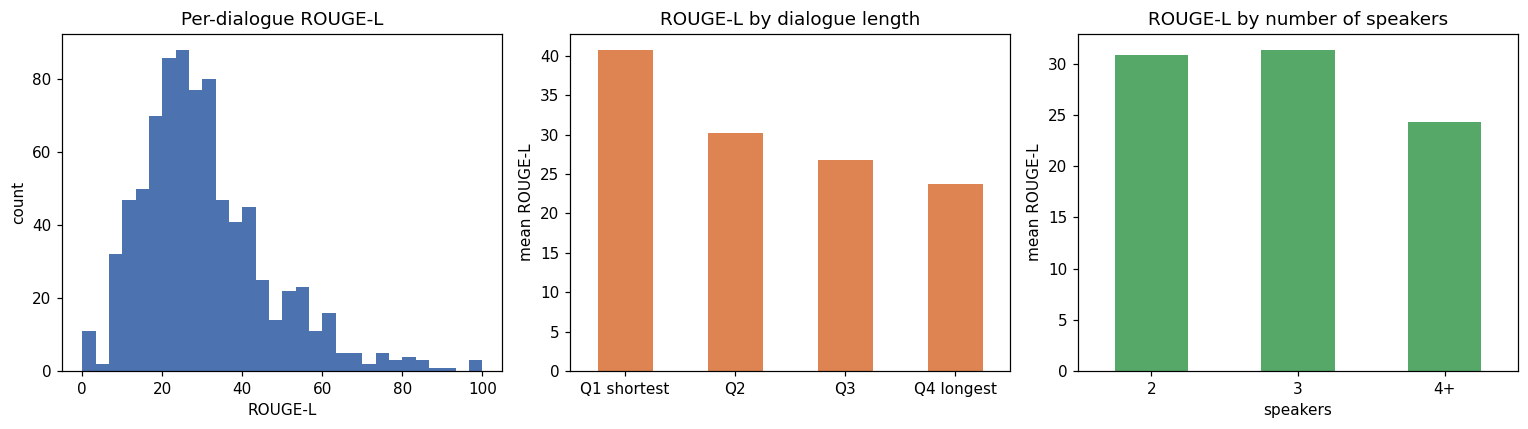

Dialogues per speaker group: {'2': 626, '3': 130, '4+': 63}
Correlation, dialogue length vs ROUGE-L: -0.328
Correlation, prediction length vs reference length: 0.542


In [25]:
per = compute_rouge(preds[BEST], test_refs, aggregate=False)
an = pd.DataFrame({
    "dialogue": test_dialogues,
    "reference": test_refs,
    "prediction": preds[BEST],
    "rouge1": per["rouge1"],
    "rouge2": per["rouge2"],
    "rougeL": per["rougeL"],
})
an["dlg_words"] = an["dialogue"].str.split().str.len()
an["speakers"] = an["dialogue"].apply(lambda d: len(speakers_of(d)))
an["pred_words"] = an["prediction"].str.split().str.len()
an["ref_words"] = an["reference"].str.split().str.len()
an["length_bucket"] = pd.qcut(an["dlg_words"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
an["speaker_group"] = an["speakers"].clip(upper=4).map(lambda s: f"{s}" if s < 4 else "4+")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(an["rougeL"], bins=30, color="#4C72B0")
axes[0].set(title="Per-dialogue ROUGE-L", xlabel="ROUGE-L", ylabel="count")

an.groupby("length_bucket", observed=True)["rougeL"].mean().plot.bar(ax=axes[1], rot=0, color="#DD8452")
axes[1].set(title="ROUGE-L by dialogue length", xlabel="", ylabel="mean ROUGE-L")

an.groupby("speaker_group")["rougeL"].mean().plot.bar(ax=axes[2], rot=0, color="#55A868")
axes[2].set(title="ROUGE-L by number of speakers", xlabel="speakers", ylabel="mean ROUGE-L")
plt.tight_layout()
save_fig("error_breakdown")
plt.show()

print("Dialogues per speaker group:", an["speaker_group"].value_counts().sort_index().to_dict())
print("Correlation, dialogue length vs ROUGE-L:", round(an["dlg_words"].corr(an["rougeL"]), 3))
print("Correlation, prediction length vs reference length:", round(an["pred_words"].corr(an["ref_words"]), 3))

In [26]:
def show(rows, title):
    print("#" * 100 + f"\n{title}\n" + "#" * 100)
    for _, r in rows.iterrows():
        print(f"\n[ROUGE-L {r.rougeL:.1f} | {r.dlg_words} words | {r.speakers} speakers]")
        print(r.dialogue[:600] + ("..." if len(r.dialogue) > 600 else ""))
        print("  REF :", r.reference)
        print("  PRED:", r.prediction)

show(an.nlargest(3, "rougeL"), "BEST CASES")
show(an.nsmallest(3, "rougeL"), "WORST CASES")

####################################################################################################
BEST CASES
####################################################################################################

[ROUGE-L 100.0 | 16 words | 2 speakers]
Jake: Maaaan! you in london?!
Mike: [photo]
Mike: yeah mate! dreams coming true!
Jake: cool! congrats!
  REF : Mike is in London.
  PRED: Mike is in London.

[ROUGE-L 100.0 | 21 words | 3 speakers]
Natalie: Could anybody check if my wallet is in my room?
Jenny: I'm not home
Tobias: It's here [photo]
Natalie: phew
  REF : Natalie's wallet is in her room.
  PRED: Natalie's wallet is in her room.

[ROUGE-L 100.0 | 26 words | 3 speakers]
Maria: I'm tired of this job, I can't stand it anymore
Anastasia: I know, but calm down
Felix: don't make decisions in this rash
Maria: :(
  REF : Maria is tired of her job.
  PRED: Maria is tired of her job.
###################################################################################################

### Factual-consistency checks (heuristic)
ROUGE rewards word overlap but not correctness: "Tom will pay" and "Anna will pay" score almost the same against "Anna will pay". Two simple checks target the most damaging errors for a chat product:
* **Unsupported names:** capitalized words in the summary that never appear in the dialogue, a likely hallucination.
* **Speaker recall:** of the participants the reference summary mentions, the share the model also mentions. This shows whether it tracks *who* is involved.

These are heuristics with false positives (for example, place names or sentence-initial words), so flagged examples are listed for manual review.

In [27]:
COMMON_CAPS = {"The", "They", "She", "He", "His", "Her", "There", "Both", "Everyone", "Nobody",
               "Today", "Tomorrow", "Tonight", "Yesterday", "Monday", "Tuesday", "Wednesday",
               "Thursday", "Friday", "Saturday", "Sunday", "Christmas", "Easter"}

def unsupported_names(pred, dialogue):
    words = set(re.findall(r"\b[A-Z][a-z]{2,}\b", pred))
    dl = dialogue.lower()
    return sorted(w for w in words if w not in COMMON_CAPS and w.lower() not in dl)

def speaker_recall(pred, ref, dialogue):
    in_ref = [s for s in speakers_of(dialogue) if s.lower() in ref.lower()]
    if not in_ref:
        return np.nan
    return float(np.mean([s.lower() in pred.lower() for s in in_ref]))

an["unsupported"] = [unsupported_names(p, d) for p, d in zip(an["prediction"], an["dialogue"])]
an["speaker_recall"] = [speaker_recall(p, r, d) for p, r, d in zip(an["prediction"], an["reference"], an["dialogue"])]

flagged = an[an["unsupported"].str.len() > 0]
HALLUC_PCT = 100 * len(flagged) / len(an)
SPEAKER_RECALL_PCT = an["speaker_recall"].mean() * 100
print(f"Summaries with possibly hallucinated names: {len(flagged)}/{len(an)} ({HALLUC_PCT:.1f}%)")
print(f"Mean speaker recall: {SPEAKER_RECALL_PCT:.1f}%")
flagged[["prediction", "unsupported", "reference"]].head(5)

Summaries with possibly hallucinated names: 405/819 (49.5%)
Mean speaker recall: 55.9%


,prediction,unsupported,reference
0,Abigail's phone number is Amanda at the park. Jane doesn't know who Amanda is.,"[Abigail, Jane]",Hannah needs Betty's number but Amanda doesn't have it. She needs to contact Larry.
1,"Eric, Rob and Greg are discussing a funny episode of Russian TV.",[Greg],Eric and Rob are going to watch a stand-up on youtube.
5,"Benjamin, Sylvester and Nathaniel are meeting up for a coffee in the La casa de papel in the evening. Benjamin is going to leave his keys with French people and Nathaniel will join them.","[Nathaniel, Sylvester]",Hilary has the keys to the apartment. Benjamin wants to get them and go take a nap. Hilary is having lunch with some French people at La Cantina. Hilary is meeting them at the entrance to the conf...
8,Gilda is in a shop and needs a scarf. Leo doesn't like the fact that he doesn't get any.,[Gilda],"Beatrice wants to buy Leo a scarf, but he doesn't like scarves. She cares about his health and will buy him a scarf no matter his opinion."
10,Linda and Gina will go to a party on Friday. Linda will take her dad's car. Gina will ask her father to buy groceries.,[Linda],Wanda wants to throw a party. She asks Gina to borrow her father's car and go do groceries together. They set the date for Friday.


### Error taxonomy
We reviewed the worst cases and the flagged summaries against four error types that matter most for a chat product:
* **Speaker attribution:** an action or decision assigned to the wrong participant. This is the most harmful error because the summary looks plausible.
* **Long and multi-party chats:** more content must be compressed and more people tracked; the breakdown charts above show how scores change with length and speaker count.
* **Generic summaries:** safe templates ("X and Y are talking about …") that score moderate ROUGE but carry little information.
* **Hallucinated details:** names, times, or places not present in the conversation, estimated by the heuristic check above.

**Our observations from this run**
* **Hallucinated names are the dominant error.** 49.5% of summaries contain a name that isn't in the chat, and speaker recall is 55.9%. Names that are common in the training data come through correctly: "Mike is in London." and "Natalie's wallet is in her room." both match their references exactly. Unusual names are swapped for plausible ones: in the football chat between Richie and Clay, the model wrote "Barry and Phil are congratulating each other on winning the ball." The rest of a summary is often roughly right even when the names are wrong, which makes these errors easy to miss.
* **Numbers and times get changed.** In the Acme demo (Section 7), a 9:30 start became "8:30" and "20 min late" became "10 minutes late". For a chat product these are as damaging as wrong names.
* **Long and multi-party chats score lower.** Mean ROUGE-L is 40.7 on the shortest quarter of chats and 23.7 on the longest (correlation between length and ROUGE-L: −0.33). Two-speaker chats score 30.8 and chats with three or more speakers 29.0.
* **Fully unrelated summaries, the MVP draft's main failure, are now uncommon** but still appear among the worst cases, for example "Jorge has a fondness for LEGO." for a chat about a favourite dinosaur.
* **Summaries are a little short:** 15.3 words on average versus 20.0 in the references, so some details are dropped.

## 7. Deployment: Saving, Reloading, and Inference

The best model was saved in Section 4 together with both tokenizers. Here we optionally publish it to the Hugging Face Hub (the weights are roughly 1 GB, too large for a plain GitHub repository), then **reload it from disk** and confirm that it reproduces the in-memory model's output before running the demo. The same loading code is packaged in `inference.py` in the repository.

In [28]:
if PUSH_TO_HUB:
    from huggingface_hub import login, create_repo, upload_folder
    login()
    create_repo(HUB_REPO_ID, exist_ok=True)
    upload_folder(folder_path=FINAL_MODEL_DIR, repo_id=HUB_REPO_ID)
    print(f"Uploaded to https://huggingface.co/{HUB_REPO_ID}")
else:
    print(f"PUSH_TO_HUB is False: weights are in {FINAL_MODEL_DIR} only (see README for sharing).")

PUSH_TO_HUB is False: weights are in /content/drive/MyDrive/samsum-project/final_model only (see README for sharing).


In [29]:
reloaded = EncoderDecoderModel.from_pretrained(FINAL_MODEL_DIR).to(device)
r_enc_tok = AutoTokenizer.from_pretrained(os.path.join(FINAL_MODEL_DIR, "encoder_tokenizer"))
r_dec_tok = AutoTokenizer.from_pretrained(os.path.join(FINAL_MODEL_DIR, "decoder_tokenizer"))

check = test_dialogues[:5]
in_memory = generate_summaries(check, **DECODING["greedy"])
from_disk = generate_summaries(check, reloaded, r_enc_tok, r_dec_tok, **DECODING["greedy"])
n_match = sum(a == b for a, b in zip(in_memory, from_disk))
print(f"Reloaded model matches the in-memory model on {n_match}/{len(check)} test dialogues")

def summarize(dialogue, **overrides):
    """Summarize one raw chat with the reloaded model and the selected decoding strategy."""
    kw = {**DECODING[BEST], **overrides}
    return generate_summaries([clean_text(dialogue)], reloaded, r_enc_tok, r_dec_tok, **kw)[0]

Reloaded model matches the in-memory model on 4/5 test dialogues


### Demo: Acme-style group chats
Three new conversations that are not in SAMSum: a team logistics thread, a group decision with a change of plan, and a short two-person exchange.

In [30]:
demo_chats = {
    "Team offsite": """Priya: Hey team, quick update on Friday's offsite
Marcus: Is it still at the lake house?
Priya: No, we moved it to the downtown office because of the storm forecast
Jenna: Ok. What time do we start?
Priya: 9:30, breakfast is provided
Marcus: I'll bring the projector
Jenna: I can't make it before 11, I have a dentist appointment
Priya: No problem, we'll do the planning session after lunch then""",

    "Birthday gift": """Tom: Guys, Kate's birthday is next Saturday, any gift ideas?
Ola: She mentioned she wants a new yoga mat
Ben: Boring :P what about concert tickets?
Ola: Tickets for the Arctic show are like 90 each
Tom: Let's split it then, that's 30 each
Ben: Fine by me
Ola: Ok, I'll buy them tonight and send you the bank details""",

    "Running late": """Mia: Stuck in traffic, I'll be 20 min late
Leo: No worries, I'll order you a coffee
Mia: Thanks! Flat white please""",
}

demo_rows = []
for title, chat in demo_chats.items():
    s = summarize(chat)
    demo_rows.append({"chat": title, "summary": s})
    print(f"=== {title} ===\n{chat}\n\nSUMMARY: {s}\n")

=== Team offsite ===
Priya: Hey team, quick update on Friday's offsite
Marcus: Is it still at the lake house?
Priya: No, we moved it to the downtown office because of the storm forecast
Jenna: Ok. What time do we start?
Priya: 9:30, breakfast is provided
Marcus: I'll bring the projector
Jenna: I can't make it before 11, I have a dentist appointment
Priya: No problem, we'll do the planning session after lunch then

SUMMARY: Sonia, Marcus, Jenna and Jessica are going to have a project on Friday at 8:30. Marcus will bring the slides for the project.

=== Birthday gift ===
Tom: Guys, Kate's birthday is next Saturday, any gift ideas?
Ola: She mentioned she wants a new yoga mat
Ben: Boring :P what about concert tickets?
Ola: Tickets for the Arctic show are like 90 each
Tom: Let's split it then, that's 30 each
Ben: Fine by me
Ola: Ok, I'll buy them tonight and send you the bank details

SUMMARY: Kate and Finn are planning to buy a new yoga mat for Kate's birthday next Saturday.

=== Running l

In [31]:
# Export example summaries for the README and the repository
with open(os.path.join(RESULTS_DIR, "sample_summaries.md"), "w", encoding="utf-8") as f:
    f.write(f"# Example summaries ({BEST} decoding)\n\n## New Acme-style chats\n\n")
    for title, chat in demo_chats.items():
        s = next(r["summary"] for r in demo_rows if r["chat"] == title)
        f.write(f"### {title}\n\n```\n{chat}\n```\n\n**Model summary:** {s}\n\n")
    f.write("## SAMSum test examples\n\n")
    for i in random.Random(SEED + 1).sample(range(len(test_dialogues)), 5):
        f.write(f"```\n{test_dialogues[i]}\n```\n\n**Reference:** {test_refs[i]}\n\n"
                f"**Model:** {preds[BEST][i]}\n\n---\n\n")
print("Wrote", os.path.join(RESULTS_DIR, "sample_summaries.md"))

Wrote ./results/sample_summaries.md


## 8. Deployment: Findings, Challenges, Limitations, and Next Steps

### 8.1 Key findings
The cell below computes the headline findings directly from this run, writes them to `results/key_findings.md`, and updates the results section of `README.md` between the `RESULTS:START` / `RESULTS:END` markers when the README is present.

In [32]:
def df_to_md(df, index_name):
    """Render a DataFrame as a GitHub markdown table (no extra dependencies)."""
    cols = [index_name] + list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [f"{v:.2f}" if isinstance(v, float) else str(v) for v in row]
        lines.append("| " + " | ".join([str(idx)] + cells) + " |")
    return "\n".join(lines)

best_row, base_row = results_df.loc[BEST], results_df.loc["lead3_baseline"]
by_len = an.groupby("length_bucket", observed=True)["rougeL"].mean()
two_spk = an.loc[an["speakers"] == 2, "rougeL"].mean()
multi_spk = an.loc[an["speakers"] >= 3, "rougeL"].mean()
best_ckpt = trainer.state.best_model_checkpoint or ""
best_step = best_ckpt.rsplit("-", 1)[-1] if "checkpoint-" in best_ckpt else "n/a"

findings = [
    f"Decoding strategy selected on validation: **{BEST}**. Test ROUGE-1 / ROUGE-2 / ROUGE-L = "
    f"**{best_row.rouge1:.2f} / {best_row.rouge2:.2f} / {best_row.rougeL:.2f}**.",
    f"Versus the Lead-3 baseline (ROUGE-L {base_row.rougeL:.2f}): {best_row.rougeL - base_row.rougeL:+.2f} ROUGE-L "
    f"(95% bootstrap CI of the paired difference: {DIFF_LO:+.2f} to {DIFF_HI:+.2f}).",
    f"Generated summaries average {best_row.avg_words:.1f} words; reference summaries average {REF_AVG_WORDS:.1f}.",
    f"By dialogue length, mean ROUGE-L is {by_len.iloc[0]:.1f} on the shortest quartile and {by_len.iloc[-1]:.1f} on the longest.",
    f"Two-speaker chats score {two_spk:.1f} ROUGE-L; chats with 3+ speakers score {multi_spk:.1f}.",
    f"{HALLUC_PCT:.1f}% of summaries contain a capitalized name not found in the dialogue (heuristic); "
    f"speaker recall is {SPEAKER_RECALL_PCT:.1f}%.",
    f"Training took {train_minutes:.0f} min on {GPU_NAME} ({len(train_tok):,} training dialogues); "
    f"the best checkpoint was at step {best_step} (validation ROUGE-L {trainer.state.best_metric:.2f}).",
]
for f_ in findings:
    print("-", f_.replace("**", ""))

results_block = "\n".join([
    f"### Test-set results ({len(test_refs)} dialogues)", "",
    df_to_md(results_df[["rouge1", "rouge2", "rougeL", "rougeLsum", "avg_words", "ms_per_dialogue"]], "method"), "",
    "### Key findings", "",
    *[f"- {f_}" for f_ in findings], "",
    "### Figures", "",
    "![Training curves](figures/training_curves.png)", "",
    "![Test ROUGE](figures/test_rouge.png)", "",
    "![Error analysis](figures/error_breakdown.png)", "",
    "Example summaries: [results/sample_summaries.md](results/sample_summaries.md)",
])
with open(os.path.join(RESULTS_DIR, "key_findings.md"), "w", encoding="utf-8") as f:
    f.write(results_block + "\n")

START, END = "<!-- RESULTS:START -->", "<!-- RESULTS:END -->"
if os.path.exists(README_PATH):
    with open(README_PATH, encoding="utf-8") as f:
        readme = f.read()
    if START in readme and END in readme:
        readme = readme.split(START)[0] + START + "\n" + results_block + "\n" + END + readme.split(END, 1)[1]
        with open(README_PATH, "w", encoding="utf-8") as f:
            f.write(readme)
        print("\nREADME.md results section updated.")
else:
    print(f"\nREADME.md not found here; copy {RESULTS_DIR}/key_findings.md into the README results section.")

- Decoding strategy selected on validation: beam4. Test ROUGE-1 / ROUGE-2 / ROUGE-L = 37.49 / 14.09 / 30.42.
- Versus the Lead-3 baseline (ROUGE-L 24.21): +6.21 ROUGE-L (95% bootstrap CI of the paired difference: +5.08 to +7.23).
- Generated summaries average 15.3 words; reference summaries average 20.0.
- By dialogue length, mean ROUGE-L is 40.7 on the shortest quartile and 23.7 on the longest.
- Two-speaker chats score 30.8 ROUGE-L; chats with 3+ speakers score 29.0.
- 49.5% of summaries contain a capitalized name not found in the dialogue (heuristic); speaker recall is 55.9%.
- Training took 44 min on Tesla T4 (14,731 training dialogues); the best checkpoint was at step 4500 (validation ROUGE-L 28.99).

README.md not found here; copy ./results/key_findings.md into the README results section.


### 8.1b Comparison with the MVP draft
The draft's test results are kept in `results/mvp_test_results.csv`. The table below sets them beside this run. The draft model was trained on 3,000 dialogues for 940 steps at a learning rate of `5e-5`, without the `[PAD]` fix.

In [33]:
mvp_path = os.path.join(RESULTS_DIR, "mvp_test_results.csv")
if os.path.exists(mvp_path):
    mvp_df = pd.read_csv(mvp_path, index_col="method")
    mvp_best = mvp_df.drop(index="lead3_baseline")["rougeL"].idxmax()
    comparison = pd.DataFrame({
        "Lead-3 baseline": results_df.loc["lead3_baseline", ["rouge1", "rouge2", "rougeL"]],
        f"MVP draft ({mvp_best})": mvp_df.loc[mvp_best, ["rouge1", "rouge2", "rougeL"]],
        f"Final ({BEST})": results_df.loc[BEST, ["rouge1", "rouge2", "rougeL"]],
    }).T
    print(f"Final vs MVP draft, ROUGE-L: {comparison.iloc[2]['rougeL'] - comparison.iloc[1]['rougeL']:+.2f}")
    print("MVP draft reference points: 95.5% of summaries had invented names; speaker recall 1.2%")
    print(f"This run: {HALLUC_PCT:.1f}% invented names; speaker recall {SPEAKER_RECALL_PCT:.1f}%")
    display(comparison.round(2))
else:
    print(f"{mvp_path} not found; skipping the comparison with the MVP draft.")

./results/mvp_test_results.csv not found; skipping the comparison with the MVP draft.


**Comparison with the MVP draft.** The cell above printed "not found" because `results/mvp_test_results.csv` wasn't uploaded to the Colab session. The table below was added after the run, from `results/mvp_test_results.csv` and `results/test_results.csv`.

| | Lead-3 baseline | MVP draft (beam 4) | Final (beam 4) |
|---|---|---|---|
| ROUGE-1 | 31.34 | 16.70 | **37.49** |
| ROUGE-2 | 8.68 | 2.47 | **14.09** |
| ROUGE-L | 24.21 | 13.11 | **30.42** |
| ROUGE-L vs Lead-3 | — | −11.10 | **+6.21** |
| Summaries with invented names | — | 95.5% | 49.5% |
| Speaker recall | — | 1.2% | 55.9% |
| Training data | — | 3,000 chats | 14,731 chats |
| Learning rate / `[PAD]` fix | — | 5e-5 / no | 1e-4 / yes |
| Training time | — | 223 min (GTX 1650 SUPER) | 44 min (Tesla T4) |

The changes more than doubled ROUGE-L and turned a model that ignored the conversation into one that beats the extractive baseline. Invented names fell by half but remain the largest remaining problem.

### 8.2 Design choices and rationale
* **BERT encoder + GPT-2 decoder:** satisfies the BERT-based brief while using a decoder that was pre-trained to generate fluent text; both checkpoints are free and well understood.
* **Separate tokenizers:** each pre-trained half keeps the vocabulary its embeddings were trained on.
* **Dynamic padding, fp16, gradient accumulation:** make full-dataset training feasible on a free T4.
* **ROUGE-L for checkpoint selection, validation set for decoding selection:** keeps the test set untouched until final reporting.
* **Lead-3 baseline and bootstrap intervals:** put the model's scores in context and show whether gains are larger than noise.

### 8.3 Challenges and how we addressed them
| Challenge | Resolution |
|---|---|
| Encoder and decoder use different vocabularies | Two tokenizers: BERT for dialogues, GPT-2 for summaries; both saved with the model |
| GPT-2 has no padding or start token | `<|endoftext|>` as start and end token; a dedicated `[PAD]` token (added after the MVP draft) so the start position isn't masked during training; label padding masked with `-100` |
| MVP draft model ignored the conversation | Diagnosed with the hallucinated-name and speaker-recall checks; fixed the pad/start-token clash, raised the learning rate, and trained on the full dataset |
| Environment issues in the draft (Python 3.9.0 bug, `datasets` 4.x `Column` objects, CPU-only PyTorch, Jupyter hangs on Windows) | Fresh Python 3.11 environment, `list(...)` conversions, CUDA build of PyTorch, data-loader workers disabled on Windows |
| Untrained model produced garbage until special tokens were set | Set `decoder_start_token_id`, `eos_token_id`, and `pad_token_id` on both the model config and the generation config |
| Randomly initialized cross-attention | Learning-rate warm-up and a full pass over the training data before judging quality |
| Saving failed on GPT-2's tied weights | Checkpoints use PyTorch format; the final export tries safetensors and falls back automatically |
| Limited GPU memory and Colab disconnects | fp16, dynamic padding, gradient accumulation; checkpoints every evaluation with resume support |
| Risk of tuning decoding on the test set | Decoding strategy selected on validation dialogues only |
| ROUGE ignores factual errors | Added hallucinated-name and speaker-recall checks plus manual review of worst cases |
| Full-dataset training was impractical on a 4 GB local GPU (estimated 18–20 hours) | Ran on a Colab T4 with checkpoints saved to Google Drive: 44 minutes of training |

### 8.4 Revisions since the MVP draft
* **Dedicated `[PAD]` token** for GPT-2, removing the pad/start-token clash.
* **Learning rate raised** from `5e-5` to `1e-4`.
* **Full SAMSum training set** (14.7k dialogues) instead of a 3,000-dialogue subset.
* **Generation capped** at `MAX_NEW_TOKENS = 80`; the draft's undertrained model often ran to the full 128 tokens, which made beam search very slow.
* Decoding strategy is now chosen on validation data instead of the test set.
* Added bootstrap confidence intervals and a paired comparison with the baseline.
* Added a reload-from-disk check, a shareable weight export, optional Hub upload, and `inference.py`.
* Added new demo chats and an exported file of example summaries.
* Figures, metrics, and key findings are saved to disk. (The README update is automatic when the notebook runs inside the repository; for this Colab run, `results/key_findings.md` was copied into the README by hand.)
* Removed commented-out code; Google Drive and Hub upload are now configuration flags.

### 8.5 Limitations
* BERT's 512-token limit truncates very long group chats, exactly the conversations where Acme users most need help.
* Cross-attention is learned from scratch during fine-tuning; purpose-built seq2seq models such as BART or PEGASUS pre-train these layers and typically score higher on SAMSum.
* ROUGE measures overlap, not correctness; a summary with the wrong name can still score well, and the factual checks here are heuristics.
* SAMSum chats were written in English by linguists, so real Acme chats (slang, emojis, typos, multiple languages, threads spanning days) will be harder.
* **Names are hard for this architecture.** `bert-base-uncased` lowercases every name and splits unusual ones into word fragments, and GPT-2 has to spell them out again in a different vocabulary, with no mechanism to copy words directly from the chat. Common names survive this; rare ones are replaced with plausible substitutes (49.5% of summaries contain an invented name).
* Numbers and times are not always copied faithfully (9:30 became 8:30 in the demo).
* Summaries average 15 words against 20 in the references, so some details are dropped.
* Results come from one training run with one seed; variance across seeds was not measured.
* The reloaded model reproduced the in-memory model's output on 4 of 5 test chats; the difference is most likely small numerical differences on the GPU changing one word choice. All reported scores come from the in-memory model.

### 8.6 Next steps
1. **Fix name handling:** switch the encoder to `bert-base-cased` so capitalization reaches the model, and compare with `facebook/bart-base`, whose shared vocabulary and pre-trained encoder-decoder connection make copying names and numbers much easier.
2. **Track speaker recall during training**, alongside ROUGE, so name errors are visible while choosing checkpoints.
3. Compare with the BERT2BERT variant (`DECODER_NAME = "bert-base-uncased"`) and with `facebook/bart-base` as an upper reference point.
4. Tune learning rate, beam size, and length penalty (a length penalty would also address the short summaries) with a small validation sweep, and repeat the best setup over several seeds.
5. Handle long chats by chunking: summarize segments, then summarize the summaries, or switch to a long-input encoder.
6. Add a factual-consistency filter (for example, an entailment model) and suppress summaries that fail it.
7. Run a small human evaluation with Acme users that rates usefulness and correctness, not just ROUGE.

### 8.7 Business implications
The final model shows that the feature is feasible: built from free, pre-trained components and trained in 44 minutes on a free GPU, it beats the extractive baseline by 6.2 ROUGE-L and often produces correct one-line summaries of short chats ("Natalie's wallet is in her room."). A summary like that lets users catch up in seconds instead of scrolling, which supports Acme's goals of reducing information overload and keeping users engaged. It is a credible proof of concept but **not yet ready for users**: half of its summaries contain a name that isn't in the chat, and the demo shows times being changed (9:30 became 8:30). For a messaging product, wrong names and times are the errors most likely to mislead people, so fixing name handling (Section 8.6) comes before any rollout. A responsible rollout would label summaries as AI-generated, link each summary back to the original messages, start with "catch up on unread messages" in smaller groups where the model is strongest, and monitor user corrections as a quality signal.

### References
* Gliwa, B., Mochol, I., Biesek, M., & Wawer, A. (2019). SAMSum Corpus: A Human-annotated Dialogue Dataset for Abstractive Summarization. *Workshop on New Frontiers in Summarization*.
* Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL*.
* Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., & Sutskever, I. (2019). Language Models are Unsupervised Multitask Learners. OpenAI.
* Rothe, S., Narayan, S., & Severyn, A. (2020). Leveraging Pre-trained Checkpoints for Sequence Generation Tasks. *TACL*.
* Lin, C.-Y. (2004). ROUGE: A Package for Automatic Evaluation of Summaries. *ACL Workshop on Text Summarization Branches Out*.
* Lewis, M., et al. (2020). BART: Denoising Sequence-to-Sequence Pre-training for Natural Language Generation, Translation, and Comprehension. *ACL*.
* Wolf, T., et al. (2020). Transformers: State-of-the-Art Natural Language Processing. *EMNLP: System Demonstrations*.